# COVID-19 Chest X-ray Classification Using Deep Learning

**Modified from the original CatBoost notebook.** This version replaces handcrafted HOG/LBP features and CatBoost with **MobileNetV2 transfer learning**.

### Scope retained from the original notebook
- Same Kaggle COVID-19 Radiography Database location.
- All four dataset classes: `COVID`, `Lung_Opacity`, `Normal`, and `Viral Pneumonia`.
- Image exploration, class-distribution analysis, stratified train/validation/test split, class-imbalance handling, and classification evaluation.

### Important changes
- Removed HOG/LBP feature extraction and CatBoost-specific `Pool` training.
- The model learns directly from X-ray images using a pretrained convolutional neural network.
- Removed PCA and handcrafted-feature plots because they do not apply to the CNN input pipeline.
- Added model checkpointing, early stopping, learning-rate reduction, ROC-AUC, and model export.

> **Research/education only:** This model is not clinically validated and must not be used to diagnose or guide treatment. It distinguishes dataset labels; it does not establish a medical diagnosis.

In [3]:
# Kaggle environment: enable GPU in Notebook settings for faster training.
import os
import json
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    precision_score, recall_score, f1_score,
    roc_curve, auc, roc_auc_score
)
from sklearn.preprocessing import label_binarize

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.20.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


In [4]:
# Dataset path supplied by the original Kaggle notebook
BASE_PATH = Path(
    "/kaggle/input/datasets/tawsifurrahman/covid19-radiography-database/COVID-19_Radiography_Dataset"
)

# Use all four available dataset classes.
CLASSES = ["COVID", "Lung_Opacity", "Normal", "Viral Pneumonia"]
LABELS = {name: idx for idx, name in enumerate(CLASSES)}

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

if not BASE_PATH.exists():
    raise FileNotFoundError(
        f"Dataset folder not found: {BASE_PATH}. "
        "Attach the COVID-19 Radiography Database Kaggle dataset to this notebook."
    )

for class_name in CLASSES:
    image_dir = BASE_PATH / class_name / "images"
    if not image_dir.exists():
        raise FileNotFoundError(f"Missing image folder: {image_dir}")

print("Class mapping:", LABELS)
print("Dataset directory:", BASE_PATH)

Class mapping: {'COVID': 0, 'Lung_Opacity': 1, 'Normal': 2, 'Viral Pneumonia': 3}
Dataset directory: /kaggle/input/datasets/tawsifurrahman/covid19-radiography-database/COVID-19_Radiography_Dataset


In [5]:
# Count images in each selected class
VALID_EXTENSIONS = {".png", ".jpg", ".jpeg"}

class_counts = {}
for class_name in CLASSES:
    image_dir = BASE_PATH / class_name / "images"
    files = [p for p in image_dir.iterdir()
             if p.is_file() and p.suffix.lower() in VALID_EXTENSIONS]
    class_counts[class_name] = len(files)

display(pd.Series(class_counts, name="Image count").to_frame())
print("Total selected images:", sum(class_counts.values()))

,Image count
COVID,3616
Lung_Opacity,6012
Normal,10192
Viral Pneumonia,1345


Total selected images: 21165


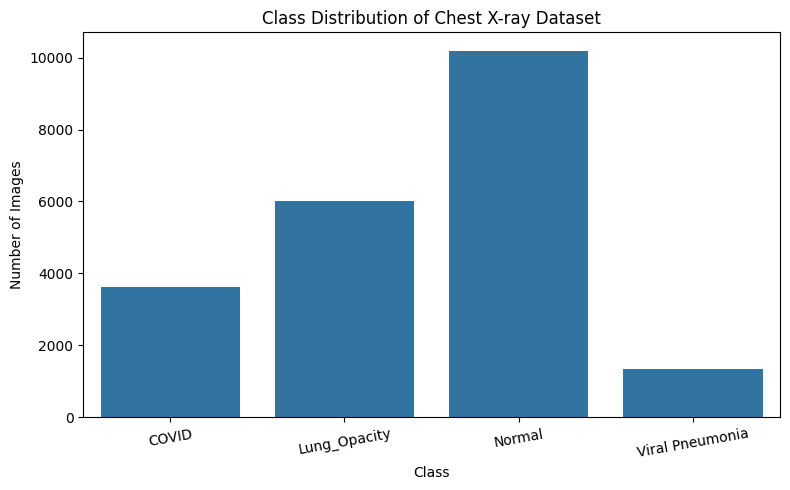

In [6]:
plt.figure(figsize=(8, 5))
sns.barplot(x=list(class_counts.keys()), y=list(class_counts.values()))
plt.title("Class Distribution of Chest X-ray Dataset")
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=10)
plt.tight_layout()
plt.show()

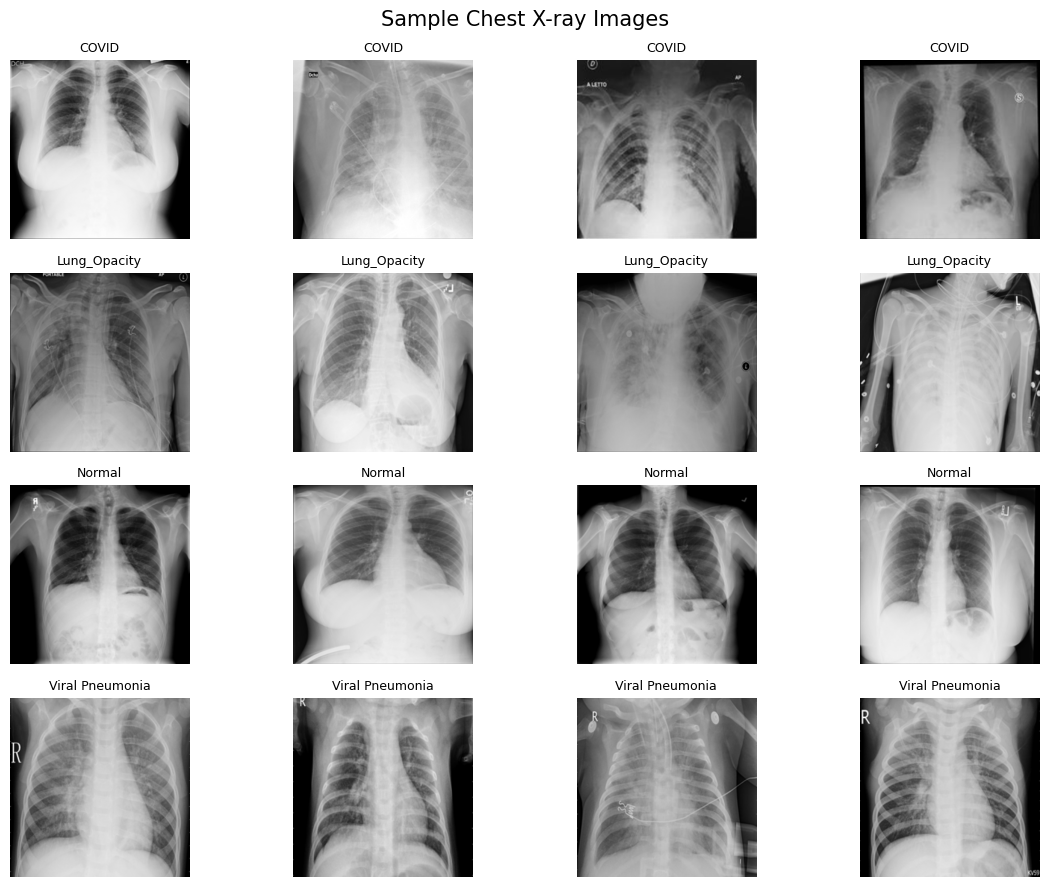

In [7]:
# Display four random X-ray examples from each class
fig, axes = plt.subplots(len(CLASSES), 4, figsize=(12, 9))
for row, class_name in enumerate(CLASSES):
    image_dir = BASE_PATH / class_name / "images"
    files = [p for p in image_dir.iterdir()
             if p.is_file() and p.suffix.lower() in VALID_EXTENSIONS]
    selected = random.sample(files, min(4, len(files)))

    for col in range(4):
        ax = axes[row, col]
        ax.axis("off")
        if col < len(selected):
            img = tf.keras.utils.load_img(selected[col], color_mode="rgb")
            ax.imshow(img)
            ax.set_title(class_name, fontsize=9)

plt.suptitle("Sample Chest X-ray Images", fontsize=15)
plt.tight_layout()
plt.show()

## Prepare image paths and labels

Unlike the original CatBoost workflow, we do **not** convert images into HOG/LBP vectors. The CNN receives resized pixel images directly.

We use a stratified split: 70% training, 15% validation, and 15% test. The test set is kept separate until final evaluation.

In [8]:
image_paths = []
image_labels = []

for class_name in CLASSES:
    image_dir = BASE_PATH / class_name / "images"
    files = sorted([
        p for p in image_dir.iterdir()
        if p.is_file() and p.suffix.lower() in VALID_EXTENSIONS
    ])
    image_paths.extend([str(p) for p in files])
    image_labels.extend([LABELS[class_name]] * len(files))

image_paths = np.asarray(image_paths)
image_labels = np.asarray(image_labels, dtype=np.int32)

print("Total images:", len(image_paths))
print("Labels shape:", image_labels.shape)
print("Class mapping:", LABELS)

# 70% train, 30% temporary
X_train, X_temp, y_train, y_temp = train_test_split(
    image_paths, image_labels,
    test_size=0.30, random_state=SEED, stratify=image_labels
)

# Split temporary data equally: 15% validation, 15% test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50, random_state=SEED, stratify=y_temp
)

print(f"Train: {len(X_train)} ({len(X_train)/len(image_paths):.1%})")
print(f"Validation: {len(X_val)} ({len(X_val)/len(image_paths):.1%})")
print(f"Test: {len(X_test)} ({len(X_test)/len(image_paths):.1%})")

Total images: 21165
Labels shape: (21165,)
Class mapping: {'COVID': 0, 'Lung_Opacity': 1, 'Normal': 2, 'Viral Pneumonia': 3}
Train: 14815 (70.0%)
Validation: 3175 (15.0%)
Test: 3175 (15.0%)


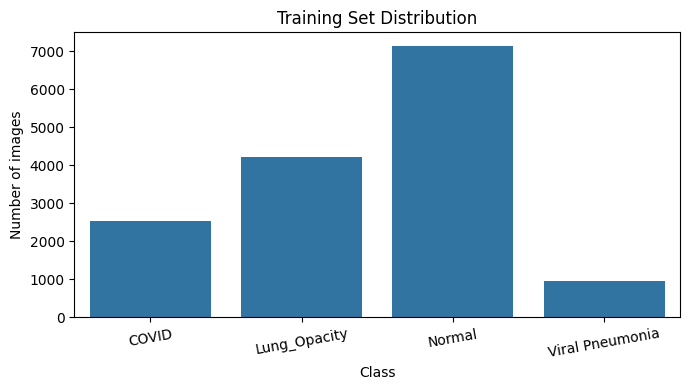

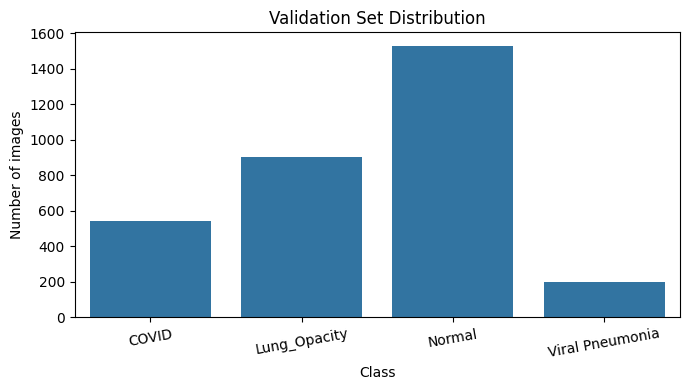

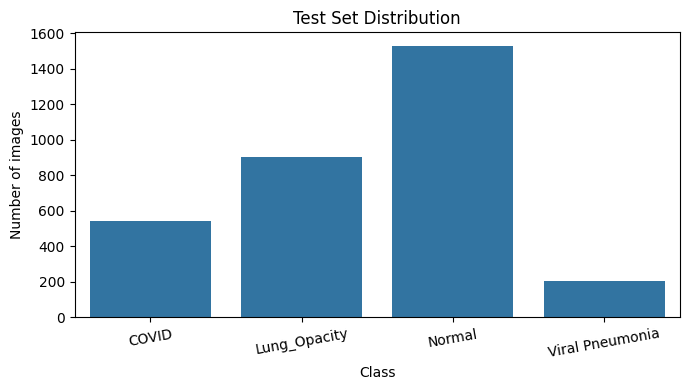

In [9]:
def plot_class_distribution(labels, title):
    counts = np.bincount(labels, minlength=len(CLASSES))
    plt.figure(figsize=(7, 4))
    sns.barplot(x=CLASSES, y=counts)
    plt.title(title)
    plt.xlabel("Class")
    plt.ylabel("Number of images")
    plt.xticks(rotation=10)
    plt.tight_layout()
    plt.show()

plot_class_distribution(y_train, "Training Set Distribution")
plot_class_distribution(y_val, "Validation Set Distribution")
plot_class_distribution(y_test, "Test Set Distribution")

## Build TensorFlow input pipelines

Images are decoded, resized to 224 × 224, and passed through MobileNetV2's required preprocessing. The pipeline loads batches rather than keeping the entire image dataset in RAM.

In [10]:
def load_and_preprocess_image(path, label):
    image_bytes = tf.io.read_file(path)
    image = tf.io.decode_image(image_bytes, channels=3, expand_animations=False)
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.keras.applications.mobilenet_v2.preprocess_input(image)
    return image, label

def make_dataset(paths, labels, training=False):
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if training:
        ds = ds.shuffle(
            buffer_size=min(len(paths), 2000),
            seed=SEED,
            reshuffle_each_iteration=True
        )
    ds = ds.map(load_and_preprocess_image, num_parallel_calls=AUTOTUNE)
    ds = ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)
    return ds

train_ds = make_dataset(X_train, y_train, training=True)
val_ds = make_dataset(X_val, y_val)
test_ds = make_dataset(X_test, y_test)

# Check one batch
for images, labels in train_ds.take(1):
    print("Image batch shape:", images.shape)
    print("Label batch shape:", labels.shape)

I0000 00:00:1793387063.584673      48 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1793387063.588626      48 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Image batch shape: (32, 224, 224, 3)
Label batch shape: (32,)


Class weights: {0: 1.4633544053733702, 1: 0.8801687262357415, 2: 0.5191687692738997, 3: 3.9317940552016983}


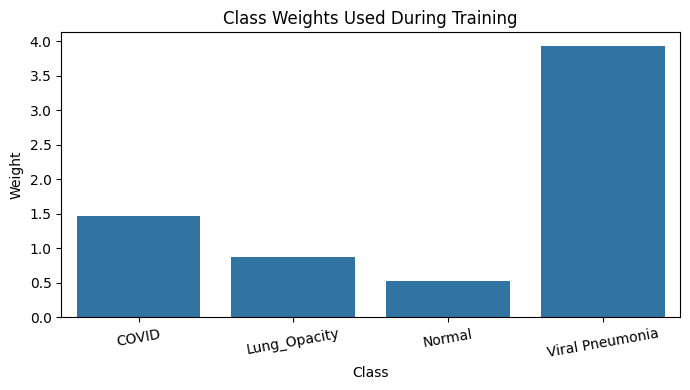

In [11]:
# Calculate class weights using training labels only
class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(y_train),
    y=y_train
)
class_weight_dict = {
    int(class_id): float(weight)
    for class_id, weight in zip(np.unique(y_train), class_weights)
}
print("Class weights:", class_weight_dict)

plt.figure(figsize=(7, 4))
sns.barplot(x=CLASSES, y=[class_weight_dict[i] for i in range(len(CLASSES))])
plt.title("Class Weights Used During Training")
plt.xlabel("Class")
plt.ylabel("Weight")
plt.xticks(rotation=10)
plt.tight_layout()
plt.show()

## Build the deep learning model: MobileNetV2

MobileNetV2 is a convolutional neural network pretrained on ImageNet. We reuse its learned visual feature extractor, freeze it initially, and train a new classification head for the four X-ray classes.

**Why transfer learning?** Training a large image model from random initialization takes more data and compute. Transfer learning is a practical choice for this deadline and dataset.

In [12]:
# Load pretrained convolutional base
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(IMG_SIZE[0], IMG_SIZE[1], 3),
    include_top=False,
    weights="imagenet"
)
base_model.trainable = False

# Data augmentation is applied only during training
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomRotation(0.03),
    tf.keras.layers.RandomZoom(0.08),
], name="data_augmentation")

inputs = tf.keras.Input(shape=(IMG_SIZE[0], IMG_SIZE[1], 3))
x = data_augmentation(inputs)
x = base_model(x, training=False)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.30)(x)
outputs = tf.keras.layers.Dense(len(CLASSES), activation="softmax")(x)

model = tf.keras.Model(inputs, outputs, name="covid_xray_mobilenetv2")

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "covid_xray_mobilenetv2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4)              │         5,124 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,263,108 (8.63 MB)

 Trainable params: 5,124 (20.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [13]:
# Save the best validation-loss model and stop when validation stops improving
OUTPUT_DIR = Path("/kaggle/working")
WEIGHTS_DIR = OUTPUT_DIR / "Weights"
WEIGHTS_DIR.mkdir(parents=True, exist_ok=True)

checkpoint_path = WEIGHTS_DIR / "best_covid_mobilenetv2.keras"

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(checkpoint_path),
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-6,
        verbose=1
    )
]

EPOCHS = 12  # Increase only if time and GPU availability permit.
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    class_weight=class_weight_dict,
    callbacks=callbacks
)

Epoch 1/12
463/463 ━━━━━━━━━━━━━━━━━━━━ 0s 958ms/step - accuracy: 0.6135 - loss: 0.8473
Epoch 1: val_loss improved from None to 0.56967, saving model to /kaggle/working/Weights/best_covid_mobilenetv2.keras

Epoch 1: finished saving model to /kaggle/working/Weights/best_covid_mobilenetv2.keras
463/463 ━━━━━━━━━━━━━━━━━━━━ 547s 1s/step - accuracy: 0.6993 - loss: 0.6511 - val_accuracy: 0.7820 - val_loss: 0.5697 - learning_rate: 0.0010
Epoch 2/12
463/463 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step - accuracy: 0.7695 - loss: 0.4888
Epoch 2: val_loss improved from 0.56967 to 0.48500, saving model to /kaggle/working/Weights/best_covid_mobilenetv2.keras

Epoch 2: finished saving model to /kaggle/working/Weights/best_covid_mobilenetv2.keras
463/463 ━━━━━━━━━━━━━━━━━━━━ 30s 64ms/step - accuracy: 0.7825 - loss: 0.4669 - val_accuracy: 0.8180 - val_loss: 0.4850 - learning_rate: 0.0010
Epoch 3/12
463/463 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step - accuracy: 0.7970 - loss: 0.4256
Epoch 3: val_loss did not improve from

## Evaluate on the held-out test set

The test set is used only after training. Report the actual results produced by your run; do not copy or invent performance numbers.

In [14]:
# Load the best checkpoint, then evaluate once on the test set
best_model = tf.keras.models.load_model(checkpoint_path)

test_loss, test_accuracy = best_model.evaluate(test_ds, verbose=1)
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.4f}")

y_prob = best_model.predict(test_ds, verbose=1)
y_pred = np.argmax(y_prob, axis=1)

print(f"Accuracy:  {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision (weighted): {precision_score(y_test, y_pred, average='weighted', zero_division=0):.4f}")
print(f"Recall (weighted):    {recall_score(y_test, y_pred, average='weighted', zero_division=0):.4f}")
print(f"F1 (weighted):        {f1_score(y_test, y_pred, average='weighted', zero_division=0):.4f}")

print("\nClassification report:")
print(classification_report(
    y_test, y_pred, labels=list(range(len(CLASSES))),
    target_names=CLASSES, zero_division=0
))

100/100 ━━━━━━━━━━━━━━━━━━━━ 93s 904ms/step - accuracy: 0.8283 - loss: 0.4606
Test loss: 0.4606
Test accuracy: 0.8283
100/100 ━━━━━━━━━━━━━━━━━━━━ 7s 58ms/step
Accuracy:  0.8283
Precision (weighted): 0.8414
Recall (weighted):    0.8283
F1 (weighted):        0.8305

Classification report:
                 precision    recall  f1-score   support

          COVID       0.70      0.85      0.77       542
   Lung_Opacity       0.86      0.79      0.83       902
         Normal       0.90      0.82      0.86      1529
Viral Pneumonia       0.67      0.98      0.79       202

       accuracy                           0.83      3175
      macro avg       0.78      0.86      0.81      3175
   weighted avg       0.84      0.83      0.83      3175



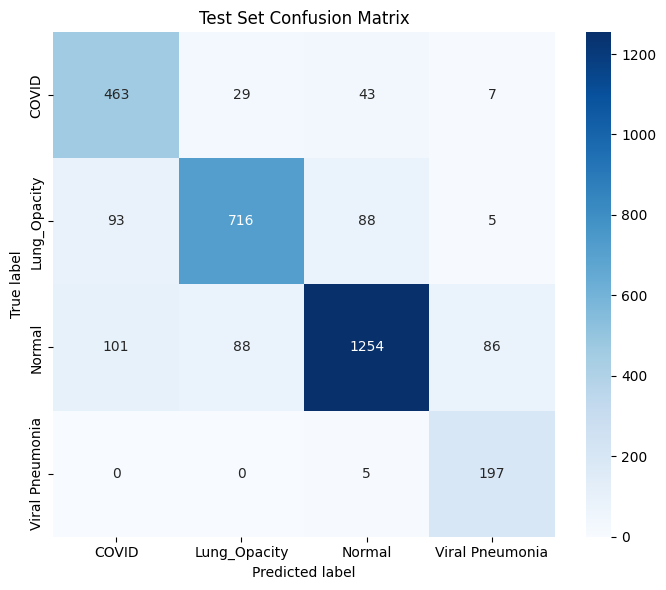

In [15]:
# Confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=list(range(len(CLASSES))))
plt.figure(figsize=(7, 6))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=CLASSES, yticklabels=CLASSES
)
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.title("Test Set Confusion Matrix")
plt.tight_layout()
plt.show()

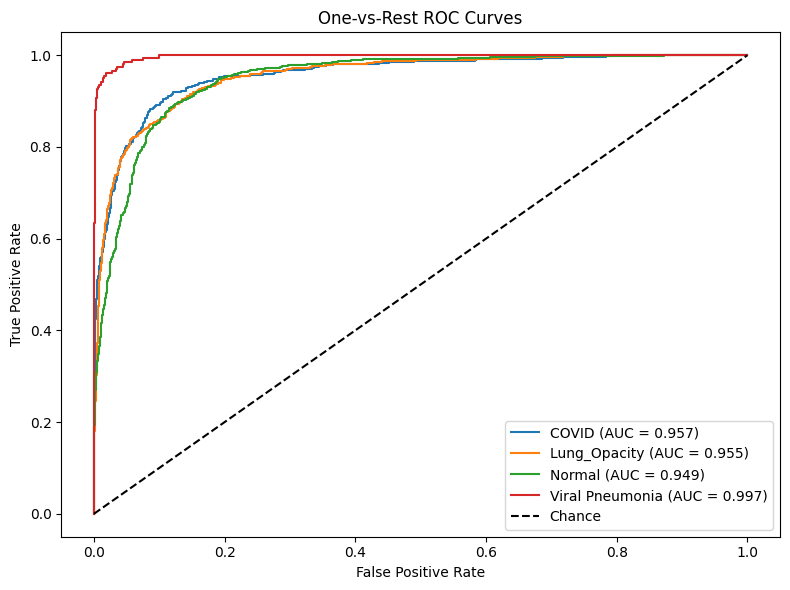

Macro ROC-AUC (one-vs-rest): 0.9645


In [16]:
# Multi-class ROC curves and macro ROC-AUC
y_test_bin = label_binarize(y_test, classes=list(range(len(CLASSES))))

plt.figure(figsize=(8, 6))
for i, class_name in enumerate(CLASSES):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_prob[:, i])
    class_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f"{class_name} (AUC = {class_auc:.3f})")

plt.plot([0, 1], [0, 1], "k--", label="Chance")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("One-vs-Rest ROC Curves")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

macro_auc = roc_auc_score(y_test_bin, y_prob, average="macro", multi_class="ovr")
print(f"Macro ROC-AUC (one-vs-rest): {macro_auc:.4f}")

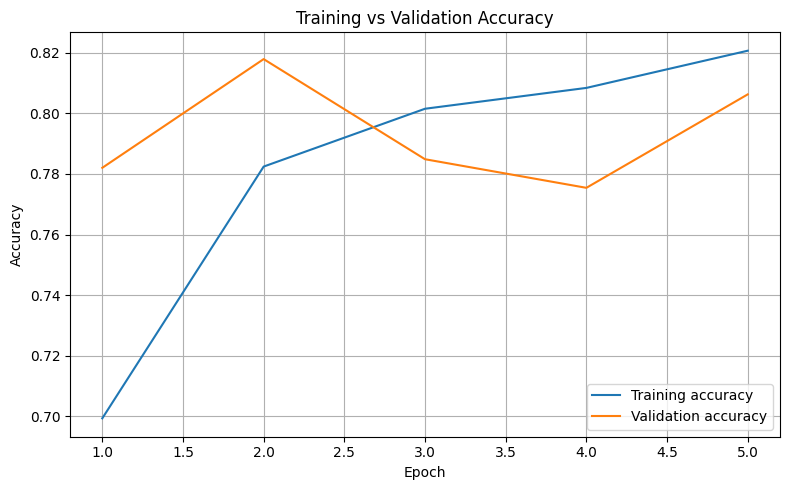

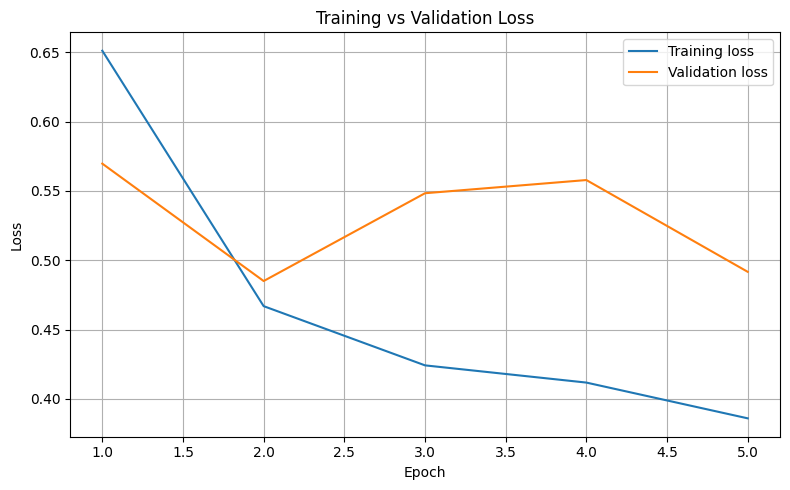

In [17]:
# Training and validation curves
history_dict = history.history
epochs_ran = range(1, len(history_dict["loss"]) + 1)

plt.figure(figsize=(8, 5))
plt.plot(epochs_ran, history_dict["accuracy"], label="Training accuracy")
plt.plot(epochs_ran, history_dict["val_accuracy"], label="Validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(epochs_ran, history_dict["loss"], label="Training loss")
plt.plot(epochs_ran, history_dict["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

## Export model and class labels

The best Keras model is saved in `/kaggle/working/Weights/`. Download the exported files from Kaggle's Output panel, then place them in your GitHub repository.

In [18]:
# Save final best model and class mapping
final_model_path = WEIGHTS_DIR / "covid_mobilenetv2.keras"
best_model.save(final_model_path)

labels_path = WEIGHTS_DIR / "class_labels.json"
with open(labels_path, "w") as f:
    json.dump(LABELS, f, indent=4)

print("Saved model:", final_model_path)
print("Saved labels:", labels_path)
print("Files:", [p.name for p in WEIGHTS_DIR.iterdir()])

Saved model: /kaggle/working/Weights/covid_mobilenetv2.keras
Saved labels: /kaggle/working/Weights/class_labels.json
Files: ['best_covid_mobilenetv2.keras', 'covid_mobilenetv2.keras', 'class_labels.json']


In [19]:
# Example prediction on one held-out test image
def predict_xray(image_path, trained_model=best_model):
    image_bytes = tf.io.read_file(str(image_path))
    image = tf.io.decode_image(image_bytes, channels=3, expand_animations=False)
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.keras.applications.mobilenet_v2.preprocess_input(image)
    probabilities = trained_model.predict(tf.expand_dims(image, axis=0), verbose=0)[0]
    predicted_index = int(np.argmax(probabilities))
    return CLASSES[predicted_index], probabilities

example_path = X_test[0]
predicted_class, probabilities = predict_xray(example_path)

print("Example image:", example_path)
print("Predicted class:", predicted_class)
print("Class probabilities:")
for class_name, probability in zip(CLASSES, probabilities):
    print(f"{class_name}: {probability:.4f}")

Example image: /kaggle/input/datasets/tawsifurrahman/covid19-radiography-database/COVID-19_Radiography_Dataset/Normal/images/Normal-8250.png
Predicted class: Normal
Class probabilities:
COVID: 0.0977
Lung_Opacity: 0.0752
Normal: 0.8269
Viral Pneumonia: 0.0002


## Limitations and responsible use

- The notebook uses all four dataset categories: `COVID`, `Lung_Opacity`, `Normal`, and `Viral Pneumonia`.
- Dataset class labels and image acquisition patterns may introduce bias. A random image-level split does not establish generalization to new hospitals or patient populations.
- ImageNet pretraining is a transfer-learning initialization, not medical-domain pretraining.
- Validation/test results are experimental and are not evidence of clinical safety.
- This model is for academic demonstration only, not medical diagnosis.


In [20]:
import shutil
from IPython.display import FileLink, display

# Compress the entire working directory
zip_path = shutil.make_archive(
    "/kaggle/working/project_backup",
    "zip",
    "/kaggle/working"
)

print("ZIP file created successfully!")
print("File size:", round(
    __import__("os").path.getsize(zip_path) / (1024 * 1024), 2
), "MB")

# Display download link
display(FileLink(zip_path))

ZIP file created successfully!
File size: 16.21 MB


/kaggle/working/project_backup.zip